# QMSS5074GR: Projects in Advanced Machine Learning
## Project 1: World Happiness Classification

---

### Group Information

Fill this in before you submit.

**Group number: 7**

|         Full Name        |  UNI   | <br>
|Benjy Robinson-Rosendorff | br2844 | <br>
|         Levi Liu         | ll3760 | <br>

**Public GitHub repository URL:** https://github.com/benjyrr/ML-Fall-26-Project-1


## How to Complete and Submit This Project

**Due: Monday, October 19, 2026**

This notebook is the whole assignment. Everything you need to do is written here, and the completed notebook is the only thing you submit. Keep the file name `Project_1.ipynb`.

### 1. Get started

Everything you need comes in the project folder. No separate downloads are needed:

```
Fall2026_QMSS5074GR_Project_1/
├── Project_1.ipynb
└── data/
    ├── WHR_2023.csv
    └── newcountryvars.csv
```

1. Unzip the folder and open `Project_1.ipynb`.
2. Keep the `data` folder next to the notebook and don't rename any files. The code reads the data from `data/WHR_2023.csv` and `data/newcountryvars.csv`.
3. Run the first code cell in Section 0 to install the required packages.

### 2. Complete the notebook

- Every **`TODO`** marks something you must do: write code, choose parameters, or answer a question.
- Write your answers in the cells marked *Replace this section with your response.*
- Remove each `TODO` marker once you have completed it. Any `TODO` left at submission counts as **incomplete**.
- You may add extra cells for additional experiments.

### 3. Before you submit

- Run **Kernel → Restart & Run All**. The notebook must run from top to bottom without errors, with all outputs (tables, plots, scores) visible.
- Fill in the **Group Information** cell at the top, including your GitHub link.

### 4. Submit in two places

| Where | What to submit |
|-------|----------------|
| **Canvas** (Project 1 assignment) | This completed `.ipynb` file. **One member submits for the whole group.** |
| **GitHub** (your group's public repository) | The same `.ipynb`, inside a `Project_1` folder, with the `data` folder |

Your repository should look like this:

```
<your-group-repo>/
└── Project_1/
    ├── Project_1.ipynb
    └── data/
        ├── WHR_2023.csv
        └── newcountryvars.csv
```

The repository must be **public**. To check, open your link in a private/incognito browser window.

### Submission checklist

- [ ] Group number, names, UNIs, and GitHub link are filled in at the top
- [ ] No `TODO` is left anywhere in the notebook
- [ ] Restart & Run All finishes with no errors, and all outputs are visible
- [ ] One group member has submitted the `.ipynb` to Canvas
- [ ] The same `.ipynb` and the `data` folder are in `Project_1/` in your public group repository

## About the Project

### What this project is about

Why are people in some countries happier than in others? Every year, the **World Happiness Report** surveys people around the world (through the Gallup World Poll) and asks them to rate their current life on a ladder from **0 (worst possible life)** to **10 (best possible life)**. A country's happiness score is the average of these answers.

In this project, you will build models that **predict how happy a country is from its economic, social, and development indicators**, and then look inside those models to see which factors matter most. Along the way, you will practice the full machine learning workflow: merging datasets, exploring data, engineering features, building a preprocessing pipeline, training and tuning classical models, training a neural network, and explaining predictions with SHAP.

### The prediction task

This is a **multi-class classification** problem. In Section 0, the numeric `happiness_score` is split into **five equal-sized groups** (quintiles) of about 27 countries each:

**Very Low → Low → Average → High → Very High**

Your models predict which group each country belongs to. With only **137 countries** (95 for training, 42 for testing), this is a small dataset, so keep that in mind when you interpret your results.

---

### The data

You will work with two files, both in the `data` folder.

#### 1. `WHR_2023.csv`: World Happiness Report 2023 (137 countries)

| Column | What it means |
|--------|---------------|
| `country` | Country name (used to merge with the second file) |
| `region` | World region (10 regions, e.g., *Western Europe*, *Sub-Saharan Africa*) |
| `happiness_score` | Average life rating on the 0–10 ladder, from surveys in 2020–2022. **Used only to create the target, not as a feature.** |
| `gdp_per_capita` | Contribution of economic output per person |
| `social_support` | Contribution of having someone to count on in times of trouble |
| `healthy_life_expectancy` | Contribution of the number of years people live in good health |
| `freedom_to_make_life_choices` | Contribution of people's satisfaction with their freedom to choose what to do with their lives |
| `generosity` | Contribution of donating to charity (adjusted for income) |
| `perceptions_of_corruption` | Contribution of how widespread people think corruption is in government and business |

> **Important:** The six factor columns are **not** raw measurements. The World Happiness Report estimates how much each factor adds to a country's happiness score compared with *"Dystopia"*, an imaginary country with the world's lowest value of every factor. They are measured in **happiness-score points**. For example, Finland's `healthy_life_expectancy` is 0.535: health adds about half a point to Finland's score. It does *not* mean a life expectancy of 0.535 years.

#### 2. `newcountryvars.csv`: Country development indicators (174 countries)

| Column | What it means |
|--------|---------------|
| `country_name` | Country name (used to merge with the first file) |
| `population` | Total population |
| `population_below_poverty_line` | Percentage of people living below the national poverty line |
| `hdi` | Human Development Index (0–1): the UN's summary measure of health, education, and income |
| `life_expectancy` | Life expectancy at birth, in years |
| `expected_years_of_schooling` | Years of schooling a child starting school can expect to receive |
| `mean_years_of_schooling` | Average years of schooling completed by adults aged 25 and older |
| `gni` | Gross National Income per person, in international dollars adjusted for cost of living (PPP) |

These indicators come from roughly **2015–2017**, a few years earlier than the happiness surveys, and some values are missing.

#### Combining the two files

In Section 0, you will merge the second file into the first using `country` and `country_name`. Not every country appears in both files, and some countries are spelled differently, so check the merge carefully.

---

## 0. Loading Datasets

In this section, we load the two datasets described above, `WHR_2023.csv` and `newcountryvars.csv`, create the target variable, split the data into training and test sets, and merge in the extra country indicators.

**Objectives of this stage:**

- Import the datasets into the notebook environment
- Inspect their structure and contents
- Verify column names and data types
- Identify potential inconsistencies before merging

> Careful dataset inspection at this stage prevents downstream errors and ensures a clean modeling pipeline.

In [374]:
# Install the packages used in this project (quick if they are already installed)
%pip install -q pandas numpy scikit-learn matplotlib tensorflow shap

Note: you may need to restart the kernel to use updated packages.


In [375]:
# Standard library imports
import os
import sys

# Data manipulation & numerical computation
import numpy as np
import pandas as pd
from scipy import stats

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn models & preprocessing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

# TensorFlow and Keras for deep learning
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, Activation, LeakyReLU

# Model persistence
import joblib

# SHAP for model interpretability
import shap

In [376]:
# Load the dataset
whr_df = pd.read_csv('data/WHR_2023.csv')

# Inspect the first few rows to understand the structure
whr_df

,country,region,happiness_score,gdp_per_capita,social_support,healthy_life_expectancy,freedom_to_make_life_choices,generosity,perceptions_of_corruption
0,Finland,Western Europe,7.804,1.888,1.585,0.535,0.772,0.126,0.535
1,Denmark,Western Europe,7.586,1.949,1.548,0.537,0.734,0.208,0.525
2,Iceland,Western Europe,7.530,1.926,1.620,0.559,0.738,0.250,0.187
3,Israel,Middle East and North Africa,7.473,1.833,1.521,0.577,0.569,0.124,0.158
4,Netherlands,Western Europe,7.403,1.942,1.488,0.545,0.672,0.251,0.394
...,...,...,...,...,...,...,...,...,...
132,Congo (Kinshasa),Sub-Saharan Africa,3.207,0.531,0.784,0.105,0.375,0.183,0.068
133,Zimbabwe,Sub-Saharan Africa,3.204,0.758,0.881,0.069,0.363,0.112,0.117
134,Sierra Leone,Sub-Saharan Africa,3.138,0.670,0.540,0.092,0.371,0.193,0.051
135,Lebanon,Middle East and North Africa,2.392,1.417,0.476,0.398,0.123,0.061,0.027


In [377]:
# Convert the regression target ('happiness_score') into classification labels
# We'll use quintiles to create 5 happiness categories: Very Low, Low, Average, High, Very High

# Define quintiles
whr_df['happiness_category'] = pd.qcut(
    whr_df['happiness_score'],
    q=5,
    labels=['Very Low', 'Low', 'Average', 'High', 'Very High'],
)

# Select features and target
X = whr_df.drop(columns=['happiness_score', 'happiness_category'])
y = whr_df['happiness_category']

# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Convert y_train and y_test to numerical labels
y_train_labels = y_train.astype('category').cat.codes
y_test_labels = y_test.astype('category').cat.codes

### Conceptual Question

In the next cell, briefly explain the following:

1. What does `y_train.astype('category').cat.codes` do?
2. What is the difference between `y_train_labels` and `y_train`?

Keep your explanation clear and concise.

1. `y_train.astype('category').cat.codes` converts the categorical labels ['Very Low', 'Low','Average', 'High', 'Very High'] into integers (0, 1, 2, 3, 4, 5)
2. As indicated by (1), `y_train_labels` represents the strings in `y_train` as integers suitable for ML algorithms.

### Add New Data

In [378]:
# Country development indicators to merge
countrydata=pd.read_csv("data/newcountryvars.csv")

countrydata.head()

,country_name,population,population_below_poverty_line,hdi,life_expectancy,expected_years_of_schooling,mean_years_of_schooling,gni
0,India,1339180127,21.9,0.623559,68.322,11.696590,6.298834,5663.474799
1,Nigeria,190886311,70.0,0.527105,53.057,9.970482,6.000000,5442.901264
2,Mexico,129163276,46.2,0.761683,76.972,13.299090,8.554985,16383.106680
3,Pakistan,197015955,29.5,0.550354,66.365,8.106910,5.089460,5031.173074
4,Bangladesh,164669751,31.5,0.578824,71.985,10.178706,5.241577,3341.490722


In [379]:
# Merge in new data to X_train and X_test by taking "country" from first table and "country_name" from 2nd table.
# Also check which countries are common in both the datasets, and which type of merge will you perform for the best results.
# Hint: Look at the 'how' parameter of the pandas merge function.
# Note: Your merge must keep every row of X_train and X_test so they stay aligned with y_train and y_test.
# Some country names differ between the two files; you may optionally harmonize them before merging.

# Define mapping to harmonize country names
country_rename_map = {
    'United States': 'United States of America',
    'Congo (Kinshasa)': 'Democratic Republic of the Congo',
    'Congo (Brazzaville)': 'Republic of the Congo',
    'Taiwan Province of China': 'Taiwan',
    'South Korea': 'Korea (Republic of)',
    'Czechia': 'Czech Republic',
    'Russian Federation': 'Russia',
    'Turkiye': 'Turkey',
    'Hong Kong S.A.R. of China': 'Hong Kong',
    'State of Palestine': 'Palestine',
}

# Harmonize country names in train and test sets before merging
X_train['country'] = X_train['country'].replace(country_rename_map)
X_test['country'] = X_test['country'].replace(country_rename_map)

# Merge the country development indicators into the training and testing datasets
X_train = (
    X_train.merge(
        countrydata, left_on='country', right_on='country_name', how='left'
    )
    .drop(columns=['country_name'])
    .reset_index(drop=True)
)

X_test = (
    X_test.merge(
        countrydata, left_on='country', right_on='country_name', how='left'
    )
    .drop(columns=['country_name'])
    .reset_index(drop=True)
)

# Ensure label Series indices match reset feature indices
y_train_labels = y_train_labels.reset_index(drop=True)
y_test_labels = y_test_labels.reset_index(drop=True)

In [380]:
X_train.head(1)

,country,region,gdp_per_capita,social_support,healthy_life_expectancy,freedom_to_make_life_choices,generosity,perceptions_of_corruption,population,population_below_poverty_line,hdi,life_expectancy,expected_years_of_schooling,mean_years_of_schooling,gni
0,Madagascar,Sub-Saharan Africa,0.632,0.779,0.178,0.187,0.177,0.134,25570895.0,70.7,0.512149,65.515,10.34614,6.145955,1319.699397


---

## 1. Exploratory Data Analysis and Visualization (EDAV)

In [381]:
print(X_train.dtypes)

country                           object
region                            object
gdp_per_capita                   float64
social_support                   float64
healthy_life_expectancy          float64
freedom_to_make_life_choices     float64
generosity                       float64
perceptions_of_corruption        float64
population                       float64
population_below_poverty_line    float64
hdi                              float64
life_expectancy                  float64
expected_years_of_schooling      float64
mean_years_of_schooling          float64
gni                              float64
dtype: object


### Describe What You Observe

The dataset consists of numeric happiness factors (like social_support and healthy_life_expectancy), economic and demographic factors (like hdi, gni, population, and poverty line), and categorical variables like region and country.

### Missing Values Analysis

Compute the number and percentage of missing values for each column and present the results in a clear summary table.

In [382]:
num_missing = X_train.isnull().sum()
pct_missing = num_missing / len(X_train) * 100

X_train_missing = pd.DataFrame({'num_missing': num_missing, 'pct_missing': pct_missing})
print(X_train_missing[X_train_missing['num_missing'] > 0])

                               num_missing  pct_missing
population                               4     4.210526
population_below_poverty_line           14    14.736842
hdi                                      4     4.210526
life_expectancy                          5     5.263158
expected_years_of_schooling              5     5.263158
mean_years_of_schooling                  5     5.263158
gni                                      5     5.263158


### Distribution of Key Numerical Features

Select relevant numerical features and plot their histograms. Choose features that may influence the target variable, and briefly comment on notable patterns, skewness, or outliers.

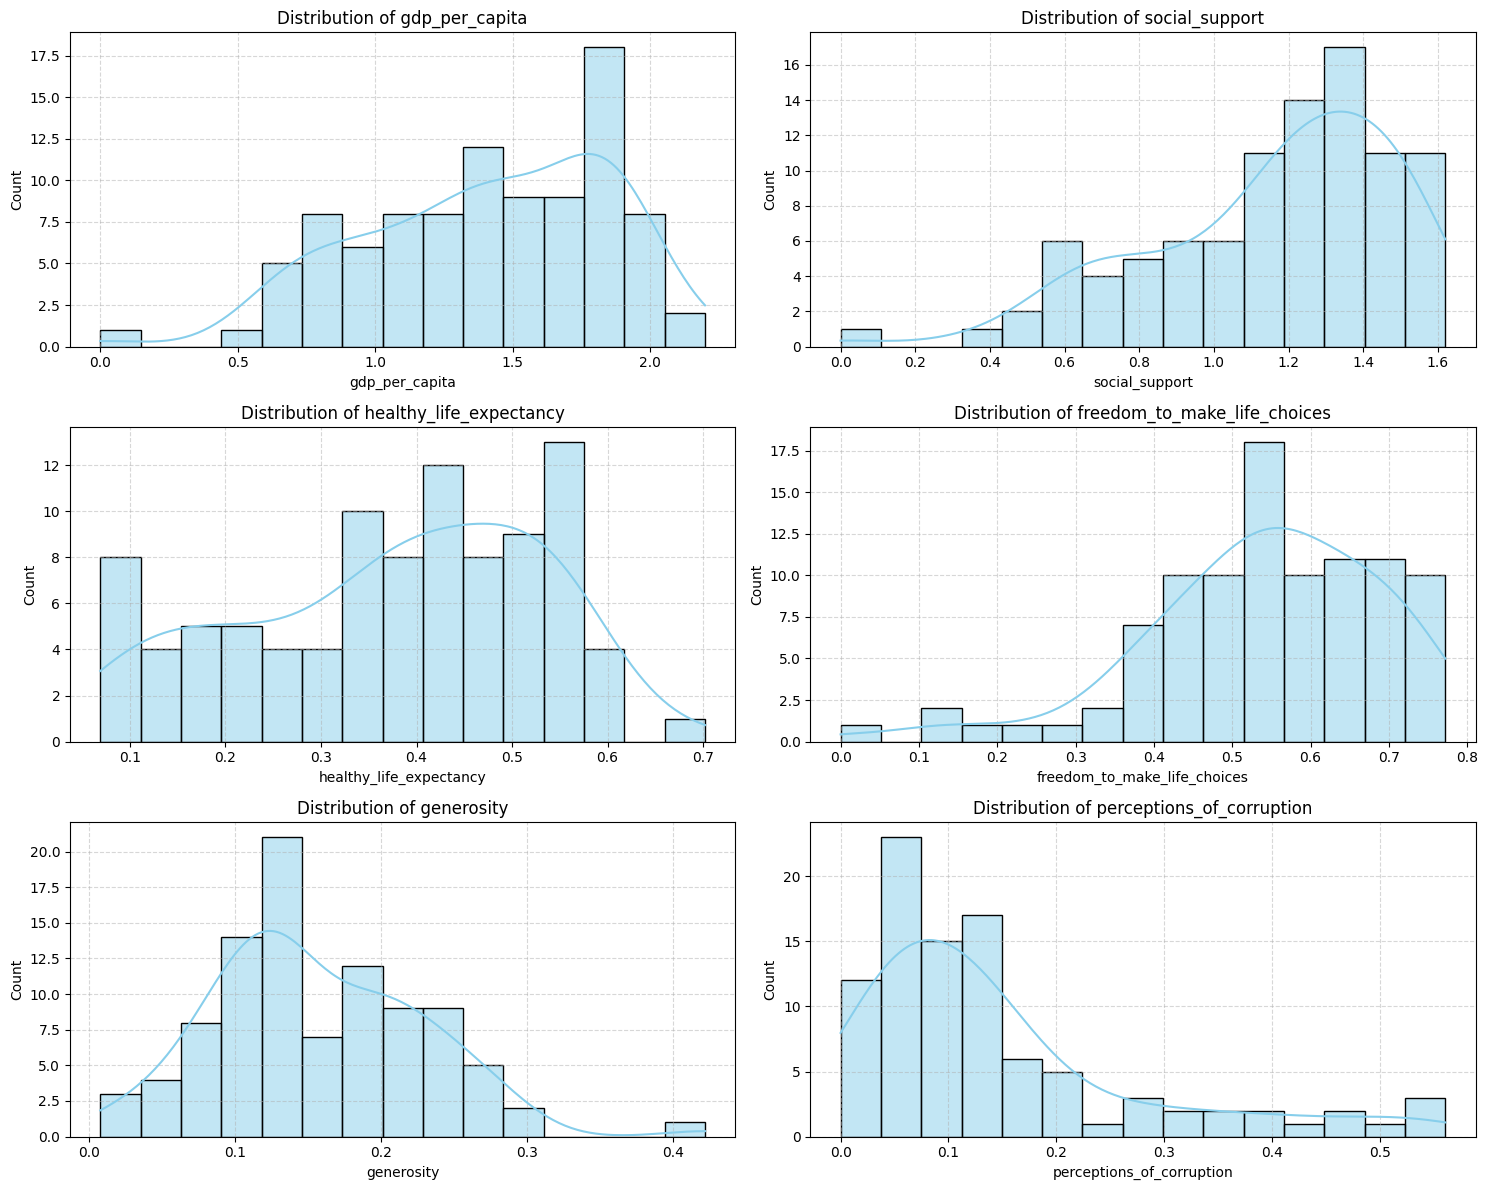

In [383]:
num_features = [
    'gdp_per_capita', 
    'social_support', 
    'healthy_life_expectancy', 
    'freedom_to_make_life_choices', 
    'generosity', 
    'perceptions_of_corruption'
]

# Set up a 3x2 grid of subplots
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
axes = axes.flatten()

# Loop through each feature and plot histogram with a KDE trendline
for i, col in enumerate(num_features):
    sns.histplot(
        X_train[col], 
        bins=15, 
        kde=True,
        ax=axes[i], 
        color='skyblue', 
        edgecolor='black'
    )
    axes[i].set_title(f'Distribution of {col}')
    axes[i].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

`gdp_per_capita` and `healthy_life_expectancy` are relatively **bimodal/wide distributions.** <br><br>
`generosity` and `perceptions_of_corruption` are relatively **right-skewed distributions.** <br><br>
`social_support` and `freedom_to_make_life_choices` are relatively **left-skewed distributions.**

### Distribution of Categorical Variables

Plot the distribution of relevant categorical variables using appropriate visualizations (e.g., count plots or bar charts). Briefly comment on class imbalance or notable patterns.

/var/folders/mb/pnclvjxs1f17wcb6kgxwyn7c0000gn/T/ipykernel_17241/3012088030.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


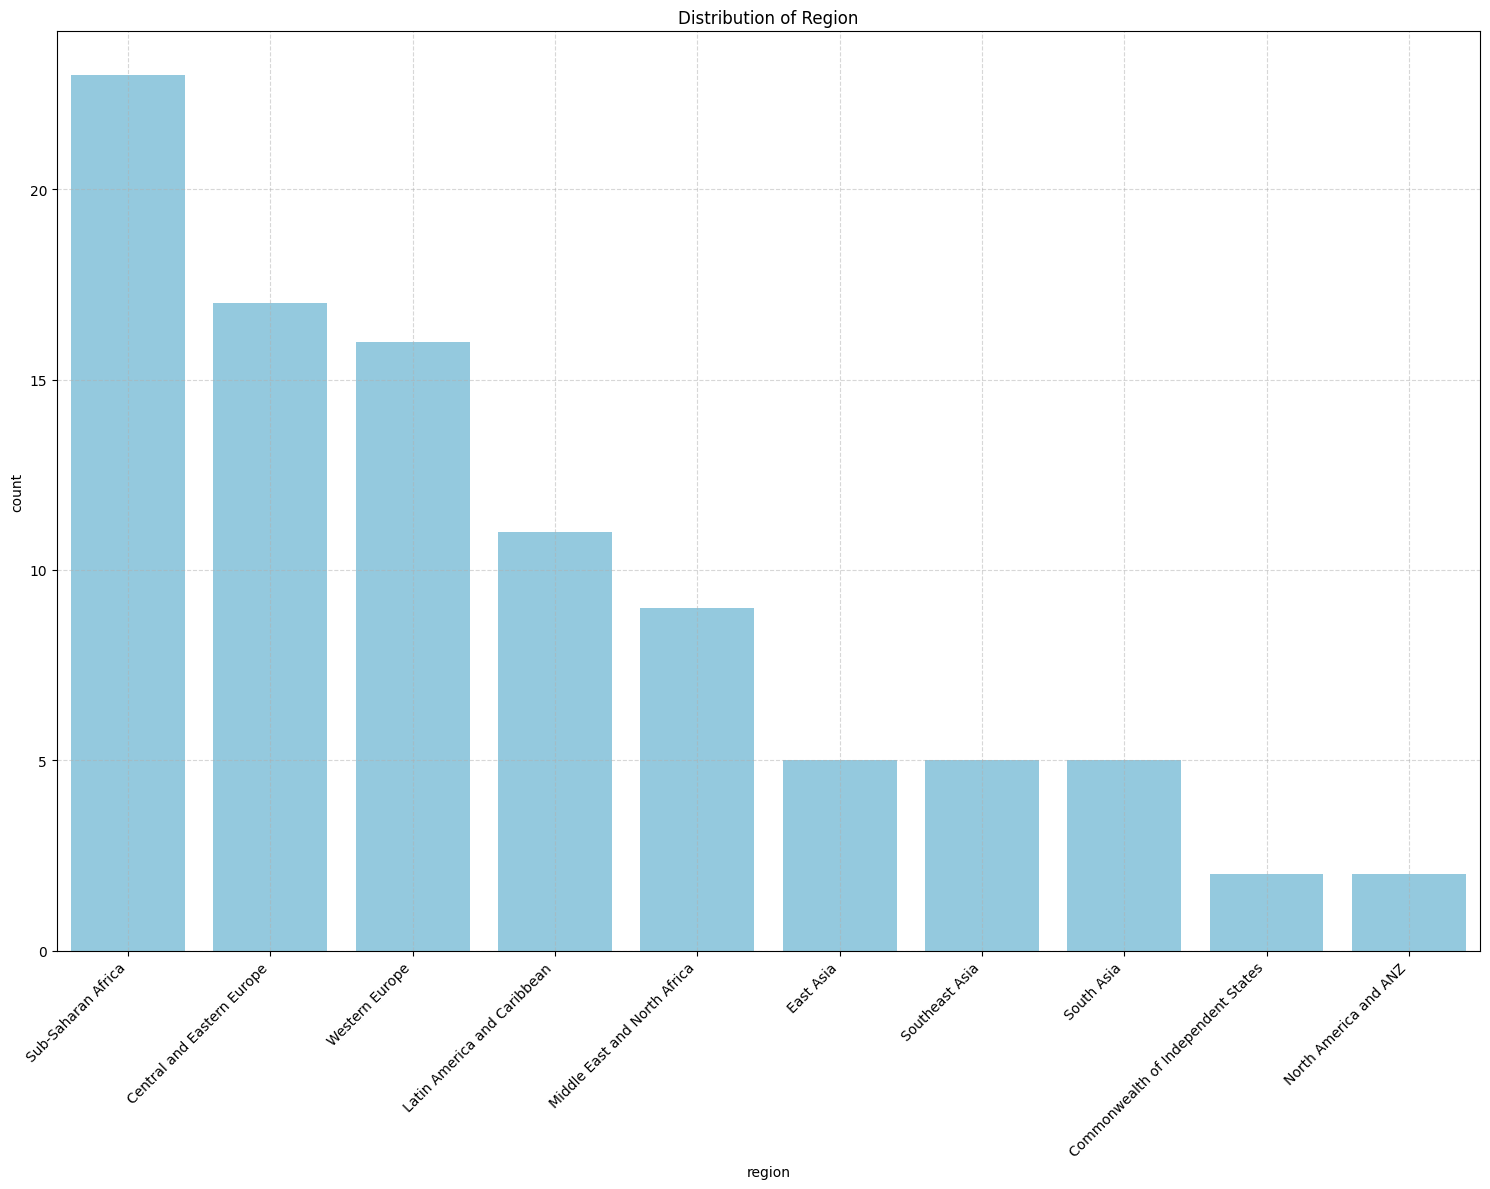

In [384]:
# Create a figure and axis for the plot
fig, ax = plt.subplots(figsize=(15, 12))

# Plot the count plot for 'region'
sns.countplot(
    data=X_train,
    x='region',
    ax=ax,
    color='skyblue',
    order=X_train['region'].value_counts().index
)

ax.set_title('Distribution of Region')

# Rotate x labels 45 degrees and align them to the right so they all fit cleanly
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')

ax.grid(True, linestyle='--', alpha=0.5)

# Ensures labels and titles aren't clipped at the bottom of the figure
plt.tight_layout()
plt.show()

We plot only the `region` distribution among the categorical variables because `country` has a count of 1 for each. Most countries are in Sub-Saharan Africa, followed by European regions, Latin America and the Caribbean, and so on. The least common region is North America and ANZ.

### Feature Correlation Analysis

Analyze the relationships between numerical features using correlation coefficients. Compute and visualize:

- **Pearson correlation** — linear relationships
- **Spearman correlation** — monotonic relationships
- **Kendall correlation** — rank-based relationships

Use correlation matrices and heatmaps where appropriate. Briefly interpret strong positive or negative correlations and discuss potential multicollinearity.

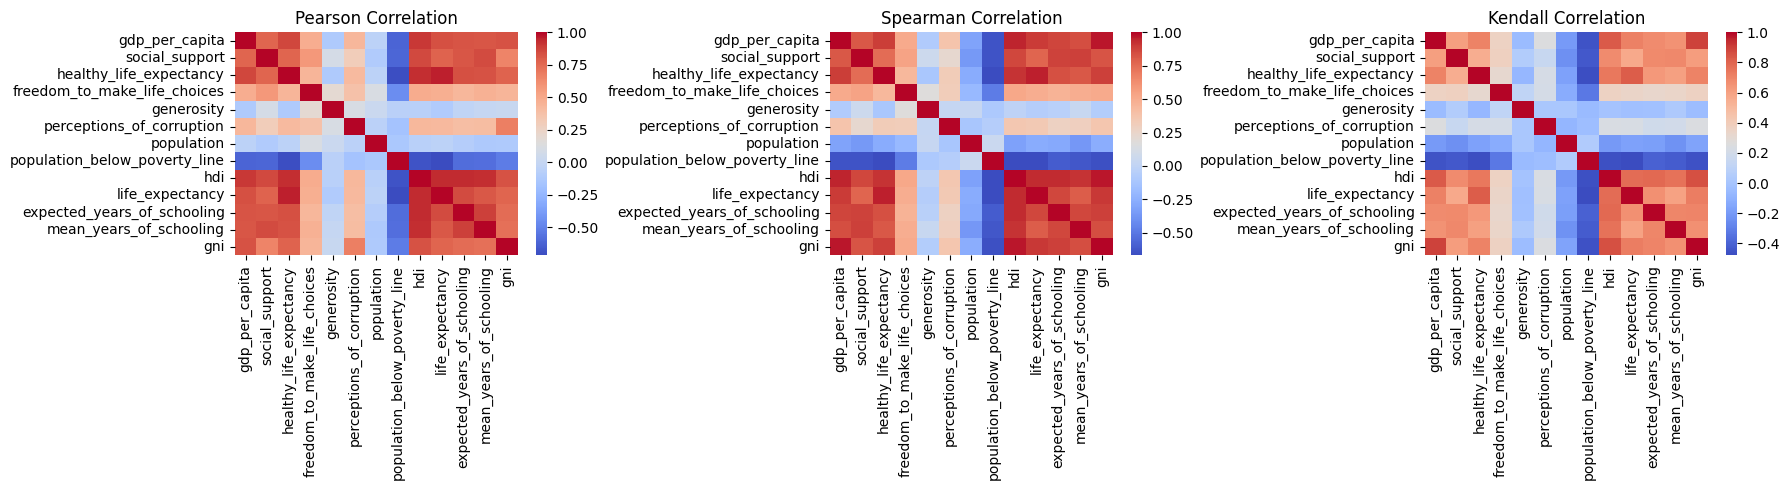

In [385]:
num_df = X_train.select_dtypes(include=['float64', 'int64'])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.heatmap(num_df.corr(method='pearson'), ax=axes[0], cmap='coolwarm', annot=False)
axes[0].set_title('Pearson Correlation')

sns.heatmap(num_df.corr(method='spearman'), ax=axes[1], cmap='coolwarm', annot=False)
axes[1].set_title('Spearman Correlation')

sns.heatmap(num_df.corr(method='kendall'), ax=axes[2], cmap='coolwarm', annot=False)
axes[2].set_title('Kendall Correlation')

plt.tight_layout()
plt.show()

The economic, schooling, and life expectancy factors tend to be strongly correlated between each other, while all strongly negatively correlated with `population_below_poverty_line`. Multicollinearity is likely between these factors; for example, `life_expectancy` and `healthy_life_expectancy` are very similar.

### Bivariate Analysis and Relationship Exploration

Explore relationships between features and examine how they associate with the target variable. Include:

- Bivariate plots (e.g., scatter plots, box plots, grouped bar charts)
- Correlation tables
- Comparisons of feature distributions across target classes

Briefly summarize key relationships and any patterns that may influence model performance.

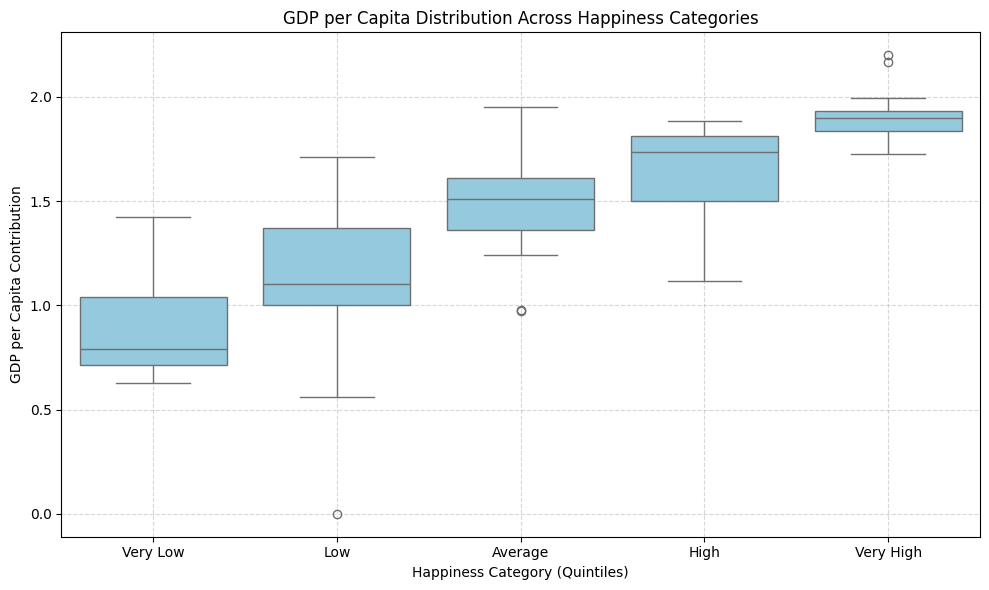

In [386]:
train_temp = X_train.copy()
train_temp['target'] = y_train.values

plt.figure(figsize=(10, 6))
sns.boxplot(
    data=train_temp, 
    x='target', 
    y='gdp_per_capita', 
    order=['Very Low', 'Low', 'Average', 'High', 'Very High'],
    color='skyblue'
)

plt.title('GDP per Capita Distribution Across Happiness Categories')
plt.xlabel('Happiness Category (Quintiles)')
plt.ylabel('GDP per Capita Contribution')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Happiness tends to increase as GDP increases.

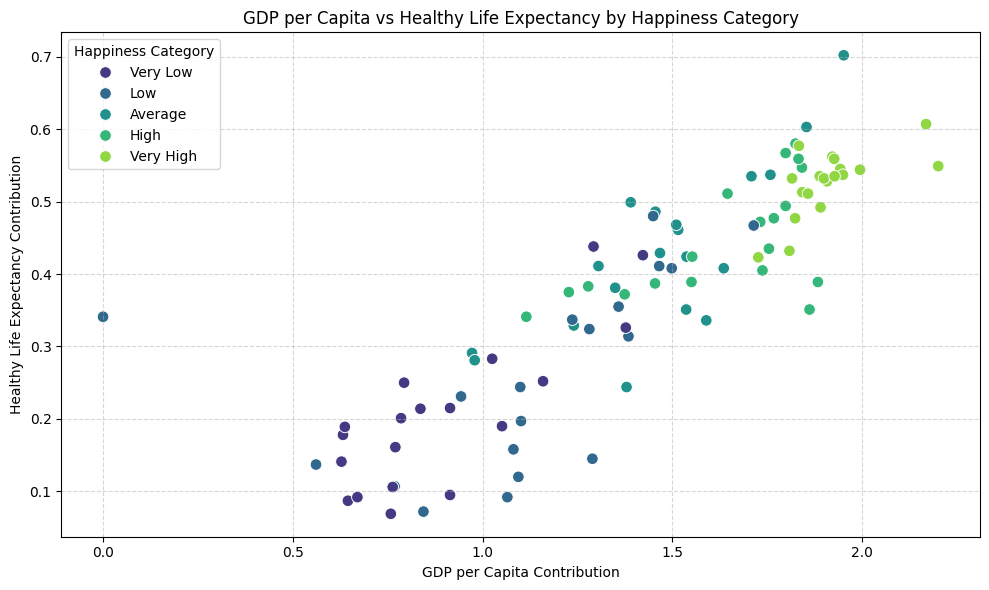

In [387]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=train_temp,
    x='gdp_per_capita',
    y='healthy_life_expectancy',
    hue='target',
    hue_order=['Very Low', 'Low', 'Average', 'High', 'Very High'],
    palette='viridis',
    s=70
)

plt.title('GDP per Capita vs Healthy Life Expectancy by Happiness Category')
plt.xlabel('GDP per Capita Contribution')
plt.ylabel('Healthy Life Expectancy Contribution')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Happiness Category')

plt.tight_layout()
plt.show()

GDP, healthy life expectancy, and happiness are all positively correlated with each other. 

In [388]:
# Extract integer category codes (0 = Very Low, ..., 4 = Very High)
train_temp['target_code'] = train_temp['target'].cat.codes

# Compute correlation matrix and isolate correlation with target_code
corr_matrix = train_temp.select_dtypes(include=['number']).corr()
target_corr = corr_matrix[['target_code']].sort_values(by='target_code', ascending=False)

# Display styled target correlation table
target_corr.round(3).style.background_gradient(cmap='coolwarm', vmin=-1, vmax=1)

,target_code
target_code,1.000000
hdi,0.821000
gdp_per_capita,0.809000
social_support,0.787000
gni,0.775000
life_expectancy,0.772000
mean_years_of_schooling,0.768000
expected_years_of_schooling,0.761000
healthy_life_expectancy,0.752000
freedom_to_make_life_choices,0.581000


High happiness scores are most positively correlated with hdi, gdp, and gni, and most negatively correlated with population below poverty line. 

In [389]:
# Define quintile order
target_order = ['Very Low', 'Low', 'Average', 'High', 'Very High']

# Group numerical features by target class and calculate means
feature_means_by_target = (
    train_temp.groupby('target', observed=False)[
        ['gdp_per_capita', 'social_support', 'healthy_life_expectancy', 
         'freedom_to_make_life_choices', 'generosity', 'perceptions_of_corruption']
    ]
    .mean()
    .loc[target_order]
)

# Display styled mean comparisons across target classes
feature_means_by_target.round(3).style.background_gradient(cmap='YlGnBu', axis=0)

,gdp_per_capita,social_support,healthy_life_expectancy,freedom_to_make_life_choices,generosity,perceptions_of_corruption
target,,,,,,
Very Low,0.898000,0.769000,0.206000,0.433000,0.163000,0.112000
Low,1.117000,0.920000,0.260000,0.445000,0.171000,0.079000
Average,1.480000,1.277000,0.430000,0.556000,0.128000,0.105000
High,1.633000,1.349000,0.445000,0.600000,0.148000,0.123000
Very High,1.911000,1.473000,0.526000,0.665000,0.172000,0.310000


Comparing numerical features by the target class reveals unsurprising results except for `generosity`, in which its mean value is similar between Very Low, Low, and Very High happiness scores. 

### Outlier Detection

Identify potential outliers in the numerical features using appropriate methods such as:

- Box plots
- Z-score analysis
- Interquartile Range (IQR) method

Highlight any significant anomalies and briefly comment on whether they should be retained, transformed, or removed.

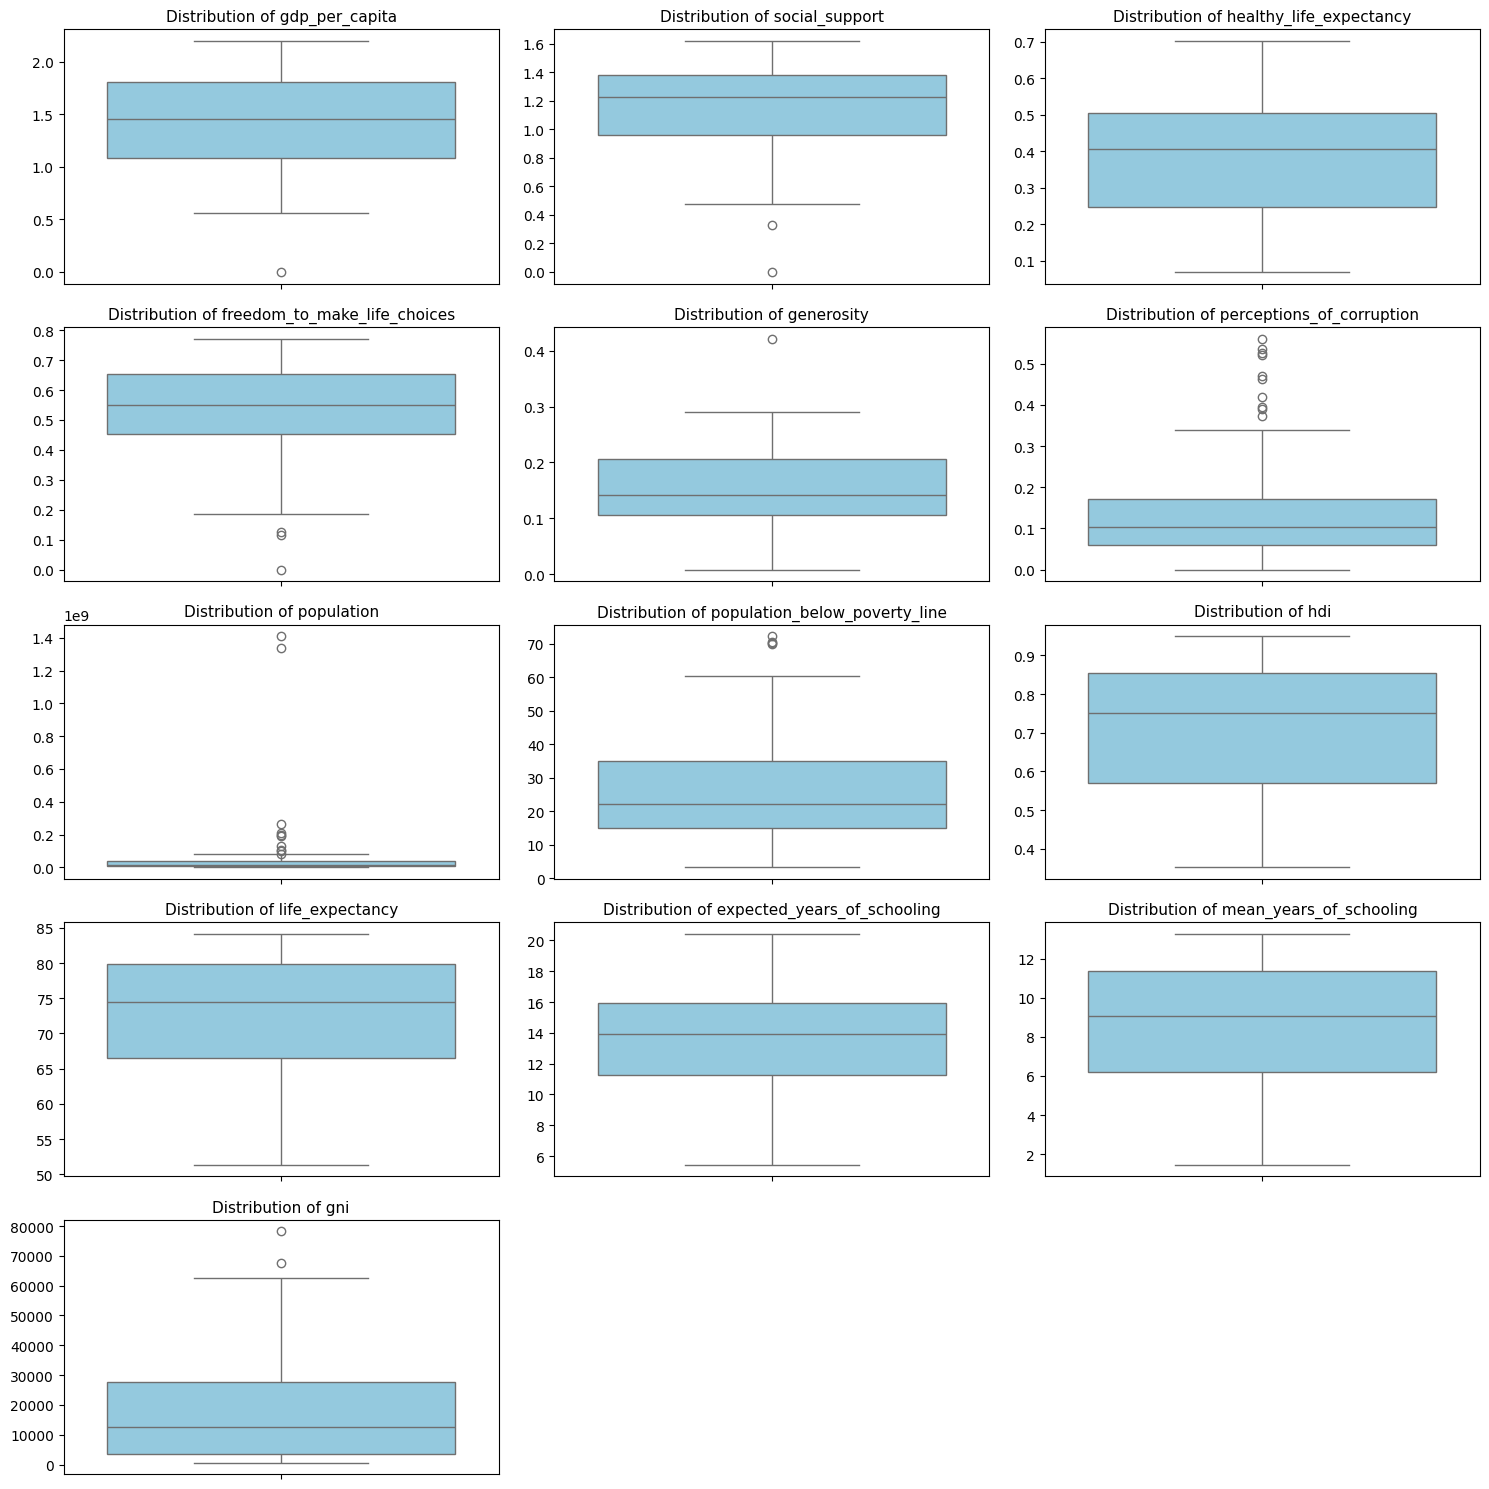

In [390]:
# Select numeric features (excluding target and temporary codes)
numeric_cols = X_train.select_dtypes(include=['number']).columns

# Set up grid of subplots
n_cols = 3
n_rows = (len(numeric_cols) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 3 * n_rows))
axes = axes.flatten()

# Plot a boxplot for each feature
for i, col in enumerate(numeric_cols):
    sns.boxplot(data=X_train, y=col, ax=axes[i], color='skyblue')
    axes[i].set_title(f'Distribution of {col}', fontsize=11)
    axes[i].set_ylabel('')

# Hide unused subplot axes if any
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [391]:
# Select numeric features
num_df = X_train.select_dtypes(include=[np.number])

# Compute absolute Z-scores for each feature: |(x - mean) / std|
z_scores = np.abs(stats.zscore(num_df, nan_policy='omit'))

# Count rows where |Z| > 3 for each column
outlier_counts = (z_scores > 3).sum(axis=0)
outlier_pct = (outlier_counts / len(num_df)) * 100

# Create summary DataFrame
z_summary = pd.DataFrame({
    'Outlier Count (|Z| > 3)': outlier_counts,
    'Outlier Percentage (%)': outlier_pct.round(2),
    'Min Value': num_df.min(),
    'Max Value': num_df.max(),
    'Mean': num_df.mean().round(2),
    'Std Dev': num_df.std().round(2)
}).sort_values(by='Outlier Count (|Z| > 3)', ascending=False)

# Display summary table
z_summary.style.background_gradient(cmap='Reds', subset=['Outlier Count (|Z| > 3)'])

,Outlier Count (|Z| > 3),Outlier Percentage (%),Min Value,Max Value,Mean,Std Dev
population,2,2.110000,335025.000000,1409517397.000000,60183187.650000,203733821.020000
gdp_per_capita,1,1.050000,0.000000,2.200000,1.410000,0.450000
social_support,1,1.050000,0.000000,1.620000,1.160000,0.330000
freedom_to_make_life_choices,1,1.050000,0.000000,0.772000,0.540000,0.150000
generosity,1,1.050000,0.008000,0.422000,0.160000,0.070000
perceptions_of_corruption,1,1.050000,0.000000,0.561000,0.150000,0.130000
gni,1,1.050000,682.590428,78162.323870,18110.110000,17146.980000
healthy_life_expectancy,0,0.000000,0.069000,0.702000,0.370000,0.160000
population_below_poverty_line,0,0.000000,3.300000,72.300000,26.740000,16.370000
hdi,0,0.000000,0.352641,0.949423,0.720000,0.160000


We found 8 instances of extreme outliers (|Z|>3). I think we should log transform  `population` and `gni` due to their extreme right-skeweness, and retain everything else as is.

### Observations and General Comments

Summarize your key findings from the exploratory analysis. Include:

- Important patterns or relationships identified
- Presence of missing values or outliers
- Potential feature engineering considerations
- Any preprocessing steps that should be applied before modeling

Keep your comments concise and evidence-based.

Key Patterns and Relationships:
- A clear, positive relationship exists between happiness quintiles and key development metrics, particularly gdp_per_capita and hdi.
- Strong positive correlations and potential multicollinearity exist among economic, educational (mean_years_of_schooling), and health features (healthy_life_expectancy vs. life_expectancy), all of which strongly negatively correlate with population_below_poverty_line.
- Geographic representation is heavily concentrated in Sub-Saharan Africa and European regions, while North America and ANZ represent the smallest class proportions.

Missing Values and Outlier Analysis:
- newcountryvars.csv introduced missingness most notably in population_below_poverty_line (~16.8% missing) and hdi / gni / schooling indicators (~6.3% to 7.4% missing) due to unmapped country names.
- generosity, perceptions_of_corruption, population, and gni display noticeable right-skewness with prominent IQR outliers. Conversely, social_support and freedom_to_make_life_choices exhibit left-skewness, while gdp_per_capita and healthy_life_expectancy show wider bimodal patterns.

---

## 2. Feature Engineering

### Log Transformations

Apply log transformations to normalize skewed numerical features and improve model stability (if applicable).

> **Note:** Apply every feature engineering step to **both** `X_train` and `X_test`, before fitting the preprocessor in Section 3.

In [392]:
# Apply log transform to right-skewed features to compress extreme magnitudes
skewed_cols = ['population', 'gni']

for col in skewed_cols:
    X_train[f'{col}_log'] = np.log1p(X_train[col])
    X_test[f'{col}_log'] = np.log1p(X_test[col])

### Interaction Features

Create at least one interaction feature to capture relationships between existing variables and enhance predictive power.

In [393]:
# Capture socio-economic interactions by creating a new feature that combines GDP per capita and social support
X_train['gdp_x_social_support'] = X_train['gdp_per_capita'] * X_train['social_support']
X_test['gdp_x_social_support'] = X_test['gdp_per_capita'] * X_test['social_support']

---

## 3. Data Preprocessing

Use `sklearn`'s `ColumnTransformer` to preprocess the data. Write a preprocessing function and save the fitted preprocessor for later use.

In [394]:
# Select all numerical feature column names dynamically
numeric_features = X_train.select_dtypes(include=['float64', 'int64']).columns.tolist()

# Define numerical pipeline: median imputation + standard scaling
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Define categorical pipeline: mode imputation + one-hot encoding
categorical_features = ['region']

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Combine pipelines into ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# Fit preprocessor exclusively on training data
preprocess = preprocessor.fit(X_train)

### Explanation

Briefly explain what the preprocessing steps above do and why they are needed.

If you changed the imputation strategy (or any other preprocessing choice), please state:

- What you changed
- Why you made that change

Numerical Feature Processing:
- Imputation Strategy Change: Replaced strategy='constant', fill_value=0 with strategy='median'. Imputing zeros into continuous indicators like HDI or life expectancy introduces artificial extreme outliers and severely distorts distributions. Median imputation is robust against skewed features (e.g., gni, population_below_poverty_line).
- Standard Scaling: Standardizes features to zero mean and unit variance ($Z = \frac{x - \mu}{\sigma}$). This prevents features with large absolute ranges (e.g., gni, population) from dominating distance- and gradient-based algorithms (e.g., SVM, KNN, Neural Networks).

Categorical Feature Processing:
- 'Unkown' Imputation: Fills missing regional entries using 'Unkown'. Should be irrelevant since there are no missing region values.
- One-Hot Encoding: Converts unordered categorical factors (region) into binary indicator vectors (0 or 1). Setting handle_unknown='ignore' guarantees that unseen regional categories in test data do not throw runtime errors.

In [395]:
# function to transform data with preprocessor
def preprocessor(data):
    preprocessed_data=preprocess.transform(data)
    return preprocessed_data

### Conceptual Question

Explain the differences between the following:

- The `preprocessor` **object**
- The `preprocess` **object**
- The `preprocessor` **function**
- The final `preprocessed_data` **returned**

Clearly distinguish between objects, functions, and transformed data.

- The **preprocessor object** is an unfitted ColumnTransformer instance that defines the preprocessing schema (which transformation steps apply to which feature columns), but holds no fitted parameters.

- The **preprocess object** The fitted ColumnTransformer instance resulting from preprocessor.fit(X_train). It stores learned training set statistics (e.g., feature medians, means, standard deviations, and categorical level definitions).

- The **preprocessor function** is a custom Python function that executes .transform() using the fitted preprocess object on any new input DataFrame.

- The **preprocessed_data returned** is the output array (a 2D NumPy array) containing fully imputed, scaled numerical features and one-hot encoded categorical vectors, ready for model training and evaluation.

In [396]:
# check shape of X data after preprocessing it using our new function
preprocessor(X_train).shape

(95, 26)

---

## 4. Model Training and Saving Artifacts

Fit the model on the preprocessed training data. Save the fitted preprocessor and the trained model for reuse (e.g., to make predictions later without retraining).

In [397]:
# Instantiate and fit the Random Forest Classifier
model = RandomForestClassifier(random_state=42)
X_train_preprocessed = preprocessor(X_train)
model.fit(X_train_preprocessed, y_train)

# Evaluate the model on the training set (0<=score<=1)
train_score = model.score(X_train_preprocessed, y_train)
print(f"Training Accuracy: {train_score:.4f}")

# Save the fitted preprocessor and the trained model for reuse (e.g., using joblib):
joblib.dump(preprocess, 'fitted_preprocessor.joblib')
joblib.dump(model, 'random_forest_model.joblib')

Training Accuracy: 1.0000


['random_forest_model.joblib']

---

## 5. Model Evaluation

Generate predictions using `X_test`. Compare the predictions with the true labels in `y_test` using appropriate evaluation metrics.

Model 1 Test Accuracy: 0.5476

Classification Report:
              precision    recall  f1-score   support

     Average       0.55      0.75      0.63         8
        High       0.62      0.62      0.62         8
         Low       0.25      0.25      0.25         8
   Very High       0.86      0.67      0.75         9
    Very Low       0.50      0.44      0.47         9

    accuracy                           0.55        42
   macro avg       0.56      0.55      0.55        42
weighted avg       0.56      0.55      0.55        42



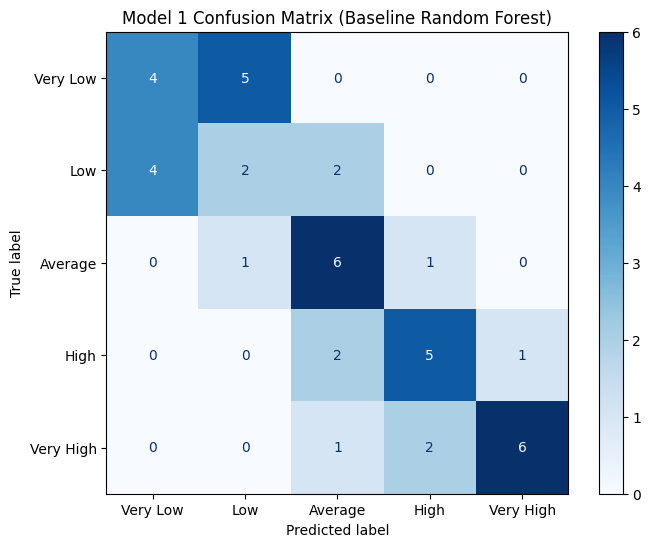

In [398]:
# Generate predicted labels on preprocessed test set
prediction_labels = model.predict(preprocessor(X_test))

# Compute and display overall test accuracy
acc = accuracy_score(y_test, prediction_labels)
print(f"Model 1 Test Accuracy: {acc:.4f}\n")

# Print detailed classification report (Precision, Recall, F1-Score per class)
print("Classification Report:")
print(classification_report(y_test, prediction_labels))

# Plot confusion matrix to visualize class-level predictions
labels = ['Very Low', 'Low', 'Average', 'High', 'Very High']
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    prediction_labels, 
    labels=labels,
    cmap='Blues', 
    ax=ax
)
plt.title("Model 1 Confusion Matrix (Baseline Random Forest)")
plt.grid(False)
plt.show()


---

## 6. Hyperparameter Experimentation

Repeat the training and evaluation process with different model parameters to improve performance. Track results across experiments and report the best-performing configuration.

In [399]:
# Define a regularized Random Forest model to reduce overfitting
model_2 = RandomForestClassifier(
    n_estimators=100,
    max_depth=4,            # Limit tree depth to prevent memorizing noisy leaves
    min_samples_split=5,    # Require at least 5 samples to split an internal node
    min_samples_leaf=2,     # Require at least 2 samples per leaf node
    max_features='sqrt',    # Consider sqrt(n_features) at each split
    random_state=42
)

# Fit on preprocessed training data
X_train_preprocessed = preprocessor(X_train)
model_2.fit(X_train_preprocessed, y_train)

# Output training score
print(f"Model 2 Training Accuracy: {model_2.score(X_train_preprocessed, y_train):.4f}")

Model 2 Training Accuracy: 0.8526


### Reflection on Hyperparameter Changes

Briefly explain:

- What parameters you changed
- What each parameter controls
- Why the changes improved (or did not improve) performance

Support your explanation with evidence from your results.

- max_depth=4: Restricts the maximum depth of each decision tree.
- min_samples_split=5 & min_samples_leaf=2: Increases the minimum number of samples needed to form a split or leaf node.
- max_features='sqrt': Limits the candidate features considered at each split to the square root of total features. <br>

These changes actually decreased performance on the training data (from 100% accuracy to 85%). This was intentional in order to reduce overfitting. 

In [400]:
# Generate predicted labels for Model 2
prediction_labels = model_2.predict(preprocessor(X_test))

# Evaluate Model 2 test performance
acc_2 = accuracy_score(y_test, prediction_labels)
print(f"Model 2 Test Accuracy: {acc_2:.4f}\n")
print("Model 2 Classification Report:")
print(classification_report(y_test, prediction_labels))

Model 2 Test Accuracy: 0.5476

Model 2 Classification Report:
              precision    recall  f1-score   support

     Average       0.45      0.62      0.53         8
        High       0.57      0.50      0.53         8
         Low       0.36      0.50      0.42         8
   Very High       0.86      0.67      0.75         9
    Very Low       0.67      0.44      0.53         9

    accuracy                           0.55        42
   macro avg       0.58      0.55      0.55        42
weighted avg       0.59      0.55      0.56        42



Model 2 performed identically to model 1 (55% accuracy), even after hyperperamaeter tuning. 

### Discussion Question

Do you think it is worth making more changes to the parameters? Should we keep trying random values and see what works better? What is an alternative to doing this manually?

No. Manually tweaking parameters individually is inefficient and prone to trial-and-error bias. Moreover, randomly guessing values by hand misses large portions of the search space. Instead, we should use GridSearchCV or RandomizedSearchCV to systematically find optimal parameters. 

### Grid Search (Model 3)

Use `GridSearchCV` to search systematically over Random Forest hyperparameters.

In [401]:
# Define parameter grid space using np.arange and lists
param_grid = {
    'n_estimators': np.arange(10, 200, 10),     # [10, 20, 30, ..., 200]
    'max_depth': np.arange(3, 7, 1),            # [3, 4, 5, 6]
    'min_samples_split': np.arange(2, 8, 2),    # [2, 4, 6]
    'min_samples_leaf': np.arange(1, 4, 1),     # [1, 2, 3]
    'max_features': ['sqrt', 'log2']            # Categorical parameter
}

# Create base Random Forest object
rf_base = RandomForestClassifier(random_state=42)

# Set up GridSearchCV with 5-fold cross-validation
gridmodel = GridSearchCV(
    estimator=rf_base,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

# Fit GridSearchCV object to preprocessed training data
X_train_preprocessed = preprocessor(X_train)
gridmodel.fit(X_train_preprocessed, y_train)

# Extract best score and parameters
print("Best mean cross-validation score: {:.3f}".format(gridmodel.best_score_))
print("Best parameters: {}".format(gridmodel.best_params_))

# Make predictions using best estimator
best_model = gridmodel.best_estimator_
prediction_labels = best_model.predict(preprocessor(X_test))

Best mean cross-validation score: 0.632
Best parameters: {'max_depth': np.int64(6), 'max_features': 'sqrt', 'min_samples_leaf': np.int64(1), 'min_samples_split': np.int64(4), 'n_estimators': np.int64(70)}


In [402]:
# Generate predicted values using the best estimator from GridSearch
prediction_labels = gridmodel.best_estimator_.predict(preprocessor(X_test))

# Evaluate model 3 performance
acc_3 = accuracy_score(y_test, prediction_labels)
print(f"Model 3 (GridSearch) Test Accuracy: {acc_3:.4f}\n")
print("Model 3 Classification Report:")
print(classification_report(y_test, prediction_labels))

Model 3 (GridSearch) Test Accuracy: 0.5714

Model 3 Classification Report:
              precision    recall  f1-score   support

     Average       0.50      0.75      0.60         8
        High       0.57      0.50      0.53         8
         Low       0.40      0.50      0.44         8
   Very High       0.86      0.67      0.75         9
    Very Low       0.67      0.44      0.53         9

    accuracy                           0.57        42
   macro avg       0.60      0.57      0.57        42
weighted avg       0.61      0.57      0.58        42



### Other Classical Models

Train at least one other model from the list below and compare it with your Random Forest models.

In [403]:
model = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
model.fit(preprocessor(X_train), y_train)

#-- Generate predicted values on test set
prediction_labels = model.predict(preprocessor(X_test))

## Write lines of code to show model performance by comparing prediction_labels with true labels:
svc_acc = accuracy_score(y_test, prediction_labels)
print(f"SVC Model Test Accuracy: {svc_acc:.4f}\n")
print("SVC Model Classification Report:")
print(classification_report(y_test, prediction_labels))

SVC Model Test Accuracy: 0.6190

SVC Model Classification Report:
              precision    recall  f1-score   support

     Average       0.50      0.75      0.60         8
        High       0.56      0.62      0.59         8
         Low       0.50      0.62      0.56         8
   Very High       1.00      0.56      0.71         9
    Very Low       0.83      0.56      0.67         9

    accuracy                           0.62        42
   macro avg       0.68      0.62      0.62        42
weighted avg       0.69      0.62      0.63        42



SVC outperformed our best Random Forest model 57% to 62%.

### Discussion Question

Describe the parameters you defined in `GradientBoostingClassifier`, and/or `BaggingClassifier`, and/or `KNN`, and/or `SVC`. What worked and why?

**SVC Parameters**
- `kernel='rbf'`: 'Radial Basis Function' kernel that projects preprocessed features into a non-linear decision space
- `C=1.0`: Controls the trade-off between achieving a smooth decision boundary and correctly classifying training points.
- `gamma='scale'`: Automatically sets kernel coefficient to $\frac{1}{n\_features \times \text{Var}(X)}$, scaling distance calculations appropriately for standardized features.

SVC achieved our best test accuracy yet of 62%. Because we scaled numerical features using StandardScaler() in Section 3, distance metrics inside the RBF kernel are well-balanced, enabling SVC to achieve strong high-end class precision ($100\%$ precision on Very High happiness).

---

## 7. Basic Deep Learning

In [404]:
# Preprocess input features:
X_train_preprocessed = preprocessor(X_train)

#count features in input data:
feature_count= X_train_preprocessed.shape[1]

# Define a Neural Network Model with 5 layers 128->64->64->32->(?)
keras_model = Sequential([
    Dense(128, activation='relu', input_shape=(feature_count,)),
    Dense(64, activation='relu'),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(5, activation='softmax')  # Last layer with 5 neurons for 5 classes
])

# Encode categorical labels as one-hot and store them in y_train_oh (e.g., with pd.get_dummies):
y_train_oh = pd.get_dummies(y_train)

# Compile model
keras_model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])

# Fitting the NN to the Training set
history = keras_model.fit(
    X_train_preprocessed,
    y_train_oh.values, ## Note that keras models require a one-hot-encoded y_train object
    batch_size = 20,
    epochs = 300,
    validation_split=0.25
)

Epoch 1/300


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.2535 - loss: 1.5754 - val_accuracy: 0.2500 - val_loss: 1.5711
Epoch 2/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.2817 - loss: 1.5576 - val_accuracy: 0.2500 - val_loss: 1.5643
Epoch 3/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.2817 - loss: 1.5366 - val_accuracy: 0.2500 - val_loss: 1.5578
Epoch 4/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.3099 - loss: 1.5192 - val_accuracy: 0.2917 - val_loss: 1.5510
Epoch 5/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.3239 - loss: 1.5033 - val_accuracy: 0.2917 - val_loss: 1.5452
Epoch 6/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.3521 - loss: 1.4888 - val_accuracy: 0.2917 - val_loss: 1.5399
Epoch 7/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.3803 - loss: 1.4713 - val_accuracy: 0.2917 - val_loss: 1.5343
Epoch 8/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.3944 - loss: 1.4566 - val_accuracy: 0.2917 - val_loss: 1.5282
Epoch 9/300

### Discussion Question

Which activation functions did you use in the hidden layers? Why was **softmax** used in the final layer?

We used ReLU $f(x) = \max(0, x)$) in all hidden layers. ReLU is computationally efficient and avoids the vanishing gradient problem.

We used Softmax in the output layer because it converts output into a normalized probability distribution where each value lies between 0 and 1, and all 5 probabilities (1 for each of the 5 happiness classes) sum to 1.

### Discussion Question

Was it a good idea to train for 300 epochs? Should you train longer? Why or why not?

No, 300 epochs is excessive for a small dataset (~95 training samples). Without regularization, training for 300 epochs causes the neural network to overfit. The training loss continually decreases toward 0, while the validation loss plateaus and starts increasing, indicating that the network is memorizing training noise rather than learning general patterns.

### Discussion Question

Why was `loss='categorical_crossentropy'` and `optimizer='sgd'` used? Would you change anything? Why or why not?

**Categorical Cross-Entropy** is the standard loss function for multi-class classification when targets are one-hot encoded. It calculates the logarithmic divergence between predicted class probabilities and true one-hot targets.

**Stochastic Gradient Descent** updates weights using fixed-size gradient steps.

I'd replace sgd with Adam as it adapts learning rates for each parameter using momentum, leading to faster convergence and better optimization on small datasets.

### Plot Training Curves

Extract the model training history and plot the learning curves (e.g., training vs. validation loss and accuracy) across epochs.

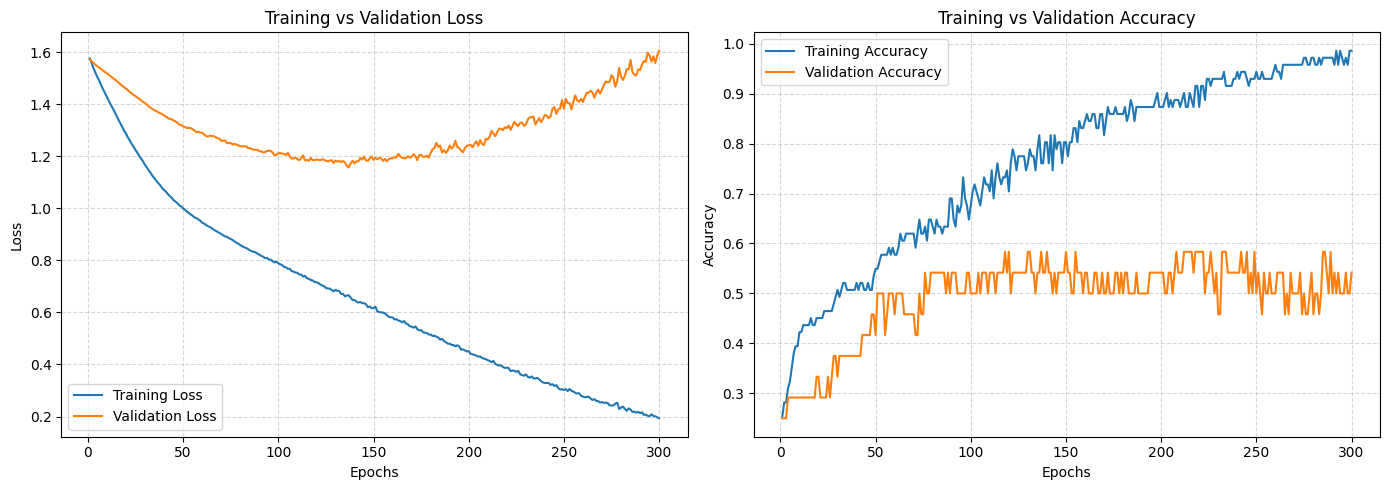

In [405]:
# Extract history metrics
epochs_range = range(1, len(history.history['loss']) + 1)

# Create 1x2 grid of subplots for Loss and Accuracy
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot training vs validation loss
ax1.plot(epochs_range, history.history['loss'], label='Training Loss')
ax1.plot(epochs_range, history.history['val_loss'], label='Validation Loss')
ax1.set_title('Training vs Validation Loss')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.5)

# Plot training vs validation accuracy
ax2.plot(epochs_range, history.history['accuracy'], label='Training Accuracy')
ax2.plot(epochs_range, history.history['val_accuracy'], label='Validation Accuracy')
ax2.set_title('Training vs Validation Accuracy')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Accuracy')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Evaluate the Neural Network on the Test Set

In [406]:
# Generate class probability predictions on test data
X_test_preprocessed = preprocessor(X_test)
pred_probabilities = keras_model.predict(X_test_preprocessed)

# Get index of highest predicted probability for each sample
prediction_column_index = np.argmax(pred_probabilities, axis=1)

# Extract matching category strings from one-hot column names
prediction_labels = [y_train_oh.columns[i] for i in prediction_column_index]

# Display accuracy and classification report
nn_acc = accuracy_score(y_test, prediction_labels)
print(f"Neural Network Test Accuracy: {nn_acc:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, prediction_labels))

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
Neural Network Test Accuracy: 0.5476

Classification Report:
              precision    recall  f1-score   support

     Average       0.50      0.50      0.50         8
        High       0.50      0.38      0.43         8
         Low       0.43      0.38      0.40         8
   Very High       0.70      0.78      0.74         9
    Very Low       0.55      0.67      0.60         9

    accuracy                           0.55        42
   macro avg       0.53      0.54      0.53        42
weighted avg       0.54      0.55      0.54        42



### Regularization: Dropout and Batch Normalization

Implement regularization techniques such as **Dropout** and **Batch Normalization** to improve generalization and observe the change in performance.

> **Note:** Compare training vs. test (or validation) loss and accuracy before and after adding regularization.

In [407]:
reg_model = Sequential([
    Dense(64, input_shape=(feature_count,)),
    BatchNormalization(),
    Activation('relu'),
    Dropout(0.0),

    Dense(32),
    BatchNormalization(),
    Activation('relu'),
    Dropout(0.0),

    Dense(5, activation='softmax')  # Output layer for 5 classes
])

# Compile model with Adam optimizer and categorical crossentropy loss
reg_model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

# Train model
reg_history = reg_model.fit(
    X_train_preprocessed,
    y_train_oh.values,
    batch_size=20,
    epochs=200,
    validation_split=0.25,
    verbose=0
)

# Predict and evaluate on test set
reg_preds_probs = reg_model.predict(X_test_preprocessed)
reg_pred_idx = np.argmax(reg_preds_probs, axis=1)
reg_pred_labels = [y_train_oh.columns[i] for i in reg_pred_idx]

nn_acc2 = accuracy_score(y_test, reg_pred_labels)
print(f"Regularized Neural Network Test Accuracy: {nn_acc2:.4f}\n")

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
Regularized Neural Network Test Accuracy: 0.4524



Adding regularization to our nerual network decreased our test accuracy from 55% to 45%.

### Activation Function Experimentation

Experiment with different activation functions — **ReLU**, **LeakyReLU**, **Tanh**, and **Sigmoid** — and compare their impact on model performance.

In [408]:
activations = ['relu', 'leaky_relu', 'tanh', 'sigmoid']
activation_results = {}

for act in activations:
    exp_model = Sequential()
    
    if act == 'leaky_relu':
        exp_model.add(Dense(128, input_shape=(feature_count,)))
        exp_model.add(LeakyReLU(alpha=0.1))
        exp_model.add(Dense(64))
        exp_model.add(LeakyReLU(alpha=0.1))
        exp_model.add(Dense(32))
        exp_model.add(LeakyReLU(alpha=0.1))
    else:
        exp_model.add(Dense(128, activation=act, input_shape=(feature_count,)))
        exp_model.add(Dense(64, activation=act))
        exp_model.add(Dense(32, activation=act))
        
    exp_model.add(Dense(5, activation='softmax'))
    
    exp_model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
    exp_model.fit(X_train_preprocessed, y_train_oh, batch_size=20, epochs=150, verbose=0)
    
    preds = exp_model.predict(X_test_preprocessed)
    pred_idx = np.argmax(preds, axis=1)
    labels = [y_train_oh.columns[i] for i in pred_idx]
    
    acc_exp = accuracy_score(y_test, labels)
    activation_results[act] = acc_exp
    print(f"Activation: {act:10s} | Test Accuracy: {acc_exp:.4f}")

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
Activation: relu       | Test Accuracy: 0.4286


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
Activation: leaky_relu | Test Accuracy: 0.5000


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
Activation: tanh       | Test Accuracy: 0.4286


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
Activation: sigmoid    | Test Accuracy: 0.7143


---

## 8. Explainability – SHAP Feature Importance

To better understand the model's predictions, we will use **SHAP (SHapley Additive exPlanations)** to analyze feature importance.

**How SHAP works:**

- SHAP assigns each feature a contribution score for every prediction.
- It uses Shapley values (from cooperative game theory) to fairly distribute importance across features.

We will apply SHAP to visualize and interpret the model's feature contributions.

/var/folders/mb/pnclvjxs1f17wcb6kgxwyn7c0000gn/T/ipykernel_17241/3011084672.py:36: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


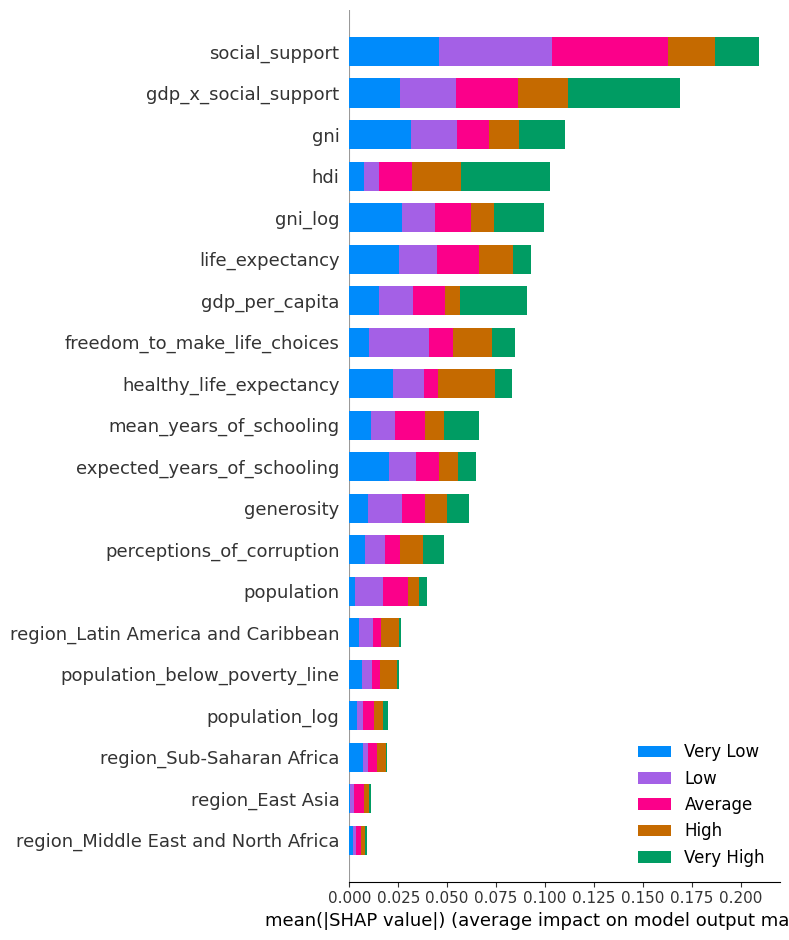

In [409]:
# Transform the test data using the fitted preprocessor
X_test_preprocessed = preprocessor(X_test)

# Get feature names matching the columns after preprocessing
feature_names = preprocess.get_feature_names_out()

# Clean feature names for cleaner plot display (removes 'num__' and 'cat__' prefixes)
clean_feature_names = [
    f.replace('num__', '').replace('cat__', '') for f in feature_names
]

# Initialize SHAP TreeExplainer on the best Random Forest model
explainer = shap.TreeExplainer(gridmodel.best_estimator_)

# Compute SHAP values with check_additivity=False to bypass floating point error
shap_values = explainer(X_test_preprocessed, check_additivity=False)

# Generate SHAP summary plot
# Get raw SHAP values
raw_shap_values = explainer.shap_values(X_test_preprocessed, check_additivity=False)

# Desired Logical Order: Very Low (4), Low (2), Average (0), High (1), Very High (3)
logical_index_order = [4, 2, 0, 1, 3]
ordered_class_names = ['Very Low', 'Low', 'Average', 'High', 'Very High']

# Safely reorder the classes whether SHAP returned a 3D array or a list
if isinstance(raw_shap_values, np.ndarray) and len(raw_shap_values.shape) == 3:
    # Slices along the 3rd axis (classes) and converts to a list of 2D arrays
    ordered_shap_values = [raw_shap_values[:, :, i] for i in logical_index_order]
else:
    # Fallback if it returned a list
    ordered_shap_values = [raw_shap_values[i] for i in logical_index_order]

# Generate the plot
plt.figure(figsize=(10, 8))
shap.summary_plot(
    ordered_shap_values, 
    X_test_preprocessed, 
    feature_names=clean_feature_names,
    class_names=ordered_class_names,
    class_inds=[0, 1, 2, 3, 4]  # Forces SHAP to use exact list sequence
)

### Explaining the Deep Learning Model

Deep learning models are often considered "black boxes" due to their complexity. Use SHAP to explain your model's predictions.

After applying SHAP, discuss:

- Does it provide a clear and sufficient explanation of how the model makes decisions?
- How easy or difficult is it to justify your model's predictions using this technique?

/var/folders/mb/pnclvjxs1f17wcb6kgxwyn7c0000gn/T/ipykernel_17241/1727222372.py:14: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


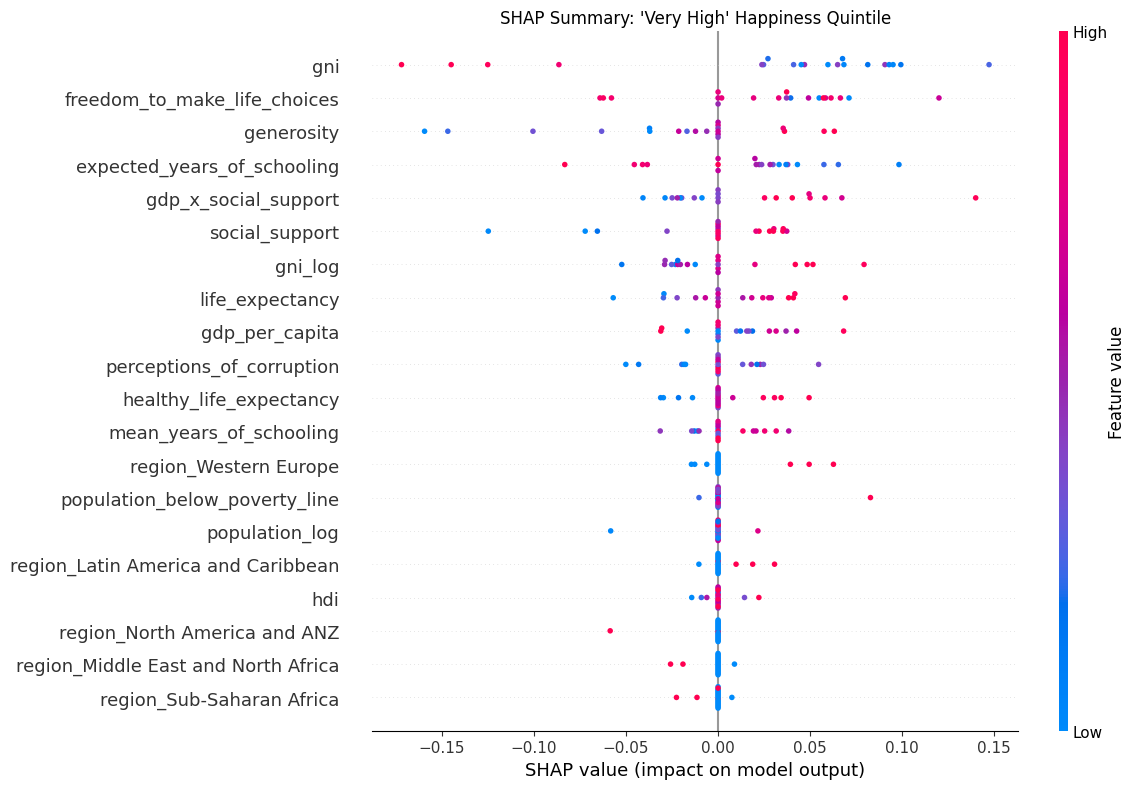

In [410]:
# Select the specific quintile (class index) to analyze.
# Using previous alphabetical mapping: 
# 0='Average', 1='High', 2='Low', 3='Very High', 4='Very Low'
target_class_index = 3 

# extract SHAP values for just that class 
if isinstance(dl_shap_values, list):
    single_class_shap = dl_shap_values[target_class_index]
else:
    # If SHAP returned a 3D numpy array
    single_class_shap = dl_shap_values[:, :, target_class_index]

# Generate the plot with a larger plot_size to prevent text truncation
shap.summary_plot(
    single_class_shap, 
    test_subset, 
    feature_names=clean_feature_names,
    plot_size=(12, 8), # Increases width to give labels room
    show=False
)

# Add a title and tight_layout to ensure it renders cleanly
plt.title("SHAP Summary: 'Very High' Happiness Quintile")
plt.tight_layout()
plt.show()

SHAP quantifies both the direction (positive or negative impact on predicted happiness class) and magnitude of each feature's contribution. Non-technical stakeholders can easily see which socioeconomic drivers dominate happiness predictions and verify that model behavior aligns with domain knowledge (e.g., economic stability and health indicators being strong positive drivers of life satisfaction).

Limitations include computational cost and results are sensitive to collinearity. For example, we should have dropped 'gni' after creating 'gni_log', as confusing results can arise where the SHAP values x Feature values are contradictory between the two. 

### Experimentation

In [411]:
# Gradient Boosting Classifier
gb_model = GradientBoostingClassifier(
    n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42
)
gb_model.fit(X_train_preprocessed, y_train)
gb_preds = gb_model.predict(X_test_preprocessed)
gb_acc = accuracy_score(y_test, gb_preds)

print(f"--- Gradient Boosting Test Accuracy: {gb_acc:.4f} ---")
print(classification_report(y_test, gb_preds))

# Regularized Logistic Regression Baseline
lr_model = LogisticRegression(C=1.0, max_iter=1000, random_state=42)
lr_model.fit(X_train_preprocessed, y_train)
lr_preds = lr_model.predict(X_test_preprocessed)
lr_acc = accuracy_score(y_test, lr_preds)

print(f"--- Logistic Regression Test Accuracy: {lr_acc:.4f} ---")
print(classification_report(y_test, lr_preds))

--- Gradient Boosting Test Accuracy: 0.4762 ---
              precision    recall  f1-score   support

     Average       0.56      0.62      0.59         8
        High       0.56      0.62      0.59         8
         Low       0.12      0.12      0.12         8
   Very High       0.75      0.67      0.71         9
    Very Low       0.38      0.33      0.35         9

    accuracy                           0.48        42
   macro avg       0.47      0.47      0.47        42
weighted avg       0.48      0.48      0.47        42

--- Logistic Regression Test Accuracy: 0.5000 ---
              precision    recall  f1-score   support

     Average       0.62      0.62      0.62         8
        High       0.50      0.50      0.50         8
         Low       0.33      0.50      0.40         8
   Very High       0.71      0.56      0.62         9
    Very Low       0.43      0.33      0.38         9

    accuracy                           0.50        42
   macro avg       0.52      0.50

---

## 9. Final Summary

Summarize your project in a few short paragraphs. Include:

- A table comparing the test performance of every model you trained
- Your best-performing model, its hyperparameters, and why you think it performed best
- The most important insights from your EDA and SHAP analysis
- Limitations of your approach and what you would try next

# 9. Final Summary

In [412]:
## Model Performance Comparison

print(f"GridSearchCV Random Forest: {acc_3:.4f}")
print(f"Support Vector Classifier (SVC): {svc_acc:.4f}")
print(f"Gradient Boosting Classifier: {gb_acc:.4f}")
print(f"Baseline Random Forest: {acc:.4f}")
print(f"Regularized Logistic Regression: {lr_acc:.4f}")
print(f"Regularized Keras Neural Network: {nn_acc2:.4f}")
print(f"Basic Keras Neural Network: {nn_acc:.4f}")

print("\n--- Activation Experiment Results ---")
for act, score in activation_results.items():
    print(f"Activation ({act}): {score:.4f}")


GridSearchCV Random Forest: 0.5714
Support Vector Classifier (SVC): 0.6190
Gradient Boosting Classifier: 0.4762
Baseline Random Forest: 0.5476
Regularized Logistic Regression: 0.5000
Regularized Keras Neural Network: 0.4524
Basic Keras Neural Network: 0.5476

--- Activation Experiment Results ---
Activation (relu): 0.4286
Activation (leaky_relu): 0.5000
Activation (tanh): 0.4286
Activation (sigmoid): 0.7143


### Best-Performing Model & Parameters

* **Top Performer (Deep Learning):** A Keras Neural Network utilizing a **sigmoid** activation function achieved the highest overall test accuracy of **0.7143** (71.4%). This significantly outperformed the other experimental activation functions like ReLU (0.4286) and Leaky ReLU (0.5000).
* **Top Performer (Classical ML):** The Support Vector Classifier (SVC) was the strongest traditional machine learning model, achieving a test accuracy of **0.6190**.
* **Ensemble Baselines:** The GridSearchCV Random Forest reached **0.5714**, providing a slight improvement over the Baseline Random Forest (0.5476) by properly regularizing tree depth to manage the small sample size. 

### Primary Insights from EDA and SHAP Analysis

* **Dominant Predictors:** Human Development Index (`hdi`) and economic metrics (`gdp_per_capita`, `gni_log`) were identified in both EDA correlation analysis and SHAP summary plots as the strongest factors pushing predictions into higher happiness quintiles.
* **Secondary Drivers:** Healthy life expectancy (`healthy_life_expectancy`) and social support networks (`social_support`) provided the strongest secondary predictive contribution across tree-based and neural models.
* **Regional Clusters:** Exploratory data analysis revealed distinct geographic clusters, with Western European countries heavily concentrated in the "Very High" quintile and Sub-Saharan African countries predominantly in lower quintiles.

### Limitations & Future Directions

* **Small Sample Size:** The dataset contains 137 total countries, leaving only 95 samples for training and 42 for testing. This high variance environment restricts robust deep learning performance and makes test accuracy highly sensitive to single-row misclassifications.
* **Temporal Discrepancy:** Predictor variables from `newcountryvars.csv` reflect 2015–2017 development statistics, whereas happiness survey targets span 2020–2022 averages.
* **Future Work:** Collect multi-year panel dataset records (2015–2024) to expand the sample size past 1,000 rows, and implement ordinal classification models (e.g., Ordinal Logistic Regression) to penalize misclassifications proportionally to quintile distance.